# GIN — Recipe Tuning on Config 2 (HI-Small)

- **Question:** which training recipe (dropout, normalisation, depth, class weight, learning rate, FFN) should the GIN family use? Tuned **once** here on config 2 (mp base / readout base), then frozen for every GIN feature config.
- **Protocol (`EXPERIMENTS.md` §2b, fixed in advance):** one knob at a time in a pre-registered order — norm → layers → FFN → pos_weight → learning rate → dropout (architecture first, then optimizer, regularisation last) — starting from the v1 recipe; 2 seeds per trial, selection on validation only, cosine T_max 100 with early stopping, best epoch from the smoothed seed-mean validation curve; a trial replaces the incumbent only if it beats it by more than max(0.01, the larger seed std); the edge rule adds one trial one step beyond a winner at the edge of its grid.
- **Everything shared** lives in `gnn_core.py` (`run_tuning_trial`, `choose_winner`, `probe_depths`, `save_recipe`). This notebook only sets the operator, the stages and paths.
- **Never touches test:** only train and validation loaders are built, no `predictions.csv`. **Resumable:** a finished trial (`trial.json` committed in the repo) is skipped, so stages can span Kaggle sessions.

## 0. Environment (Kaggle)

- Pinned PyTorch / PyG stack known to work on Kaggle GPU — do not change versions or order.
- Then clone (or pull) the public repo so the committed `gnn_core.py` is the one imported.

In [1]:
!pip uninstall -y torch torchvision torchaudio torch-scatter torch-sparse pyg_lib
!pip install torch==2.8.0 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
!pip install torch-scatter torch-sparse torch-cluster -f https://data.pyg.org/whl/torch-2.8.0+cu126.html
!pip install torch_geometric

Found existing installation: torch 2.11.0+cu128


Uninstalling torch-2.11.0+cu128:


  Successfully uninstalled torch-2.11.0+cu128


Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:


  Successfully uninstalled torchvision-0.26.0+cu128


...

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 82.2 MB/s eta 0:00:00


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.5 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.3 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━ 0.8/1.3 MB 25.0 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 19.3 MB/s eta 0:00:00


In [2]:
import os
import sys

REPO_URL = 'https://github.com/sandrokhizanishvili/gnn_for_fraudulent_patterns.git'
REPO_DIR = '/kaggle/working/gnn_for_fraudulent_patterns'
if os.path.isdir(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL} {REPO_DIR}
!git -C {REPO_DIR} log -1 --oneline
sys.path.append(REPO_DIR)

Cloning into '/kaggle/working/gnn_for_fraudulent_patterns'...


remote: Enumerating objects: 475, done.
remote: Counting objects: 100% (475/475), done.


remote: Compressing objects: 100% (420/420), done.


remote: Total 475 (delta 156), reused 365 (delta 52), pack-reused 0 (from 0)
Receiving objects: 100% (475/475), 18.14 MiB | 6.78 MiB/s, done.


Resolving deltas: 100% (156/156), done.


1159ccc (HEAD -> main, origin/main, origin/HEAD) Recipe tuning (GIN first): recipe dict in gnn_core.py (v1 reproduced bit-exactly with recipe=None), norm/FFN/early-stopping/train+val/retrain helpers; GIN_tuning.ipynb + GIN_tuning_final.ipynb; EXPERIMENTS 2b/3b, CLAUDE 3/6/7, README; gbt_core.seed_summary delegates to gnn_core


## 1. Configuration

- `STAGES`: the pre-registered knob order and grids; the winner of each stage is carried into the next.
- `TUNE`: the only change to the v1 recipe before tuning starts — cosine length 100 (early stopping decides the run length).
- `OUT_ROOT` sits **inside the repo clone**, so trials committed after an earlier session are found and skipped.

In [3]:
OPERATOR = 'gin'
CFG      = dict(mp='base', readout='base')     # config 2 — the configuration every recipe is tuned on
SEEDS    = (42, 43)                             # tuning seeds; the final retrain adds 44
TUNE     = dict(epochs=100)                     # v1 recipe + cosine T_max 100; nothing else changes before stage 1

# one knob at a time, architecture first, then optimizer, regularisation last (EXPERIMENTS.md section 2b);
# the incumbent value is in every grid, so the v1 recipe is the starting incumbent
STAGES = [
    ('s1_norm',       'norm',       ['none', 'batch', 'layer']),
    ('s2_layers',     'num_layers', [2, 4, 6]),
    ('s3_ffn',        'ffn',        [False, True]),
    ('s4_pos_weight', 'pos_weight', [8.0, 16.0]),
    ('s5_lr',         'lr',         [5e-4, 1e-3, 3e-3]),
    ('s6_dropout',    'dropout',    [0.2, 0.3, 0.4]),
]
PATIENCE, MIN_EPOCHS, EVAL_TRAIN_EVERY = 10, 20, 5   # early stopping on the smoothed val F1; train scored every 5th epoch
PROBE_DEPTHS = (2, 4, 6)                             # heaviest setting (BatchNorm + FFN) probed before stage 1

MP_DIRECTION      = 'in'     # fixed for the whole tuning
TEMPORAL_SAMPLING = False

# paths — OUT_ROOT inside the repo clone so committed trials resume
DATA_DIR = '/kaggle/input/datasets/sandrokhizanishvili/hi-small-gnn'
OUT_ROOT = f'{REPO_DIR}/Outputs/TUNING/{OPERATOR.upper()}'

import gnn_core as core
os.makedirs(OUT_ROOT, exist_ok=True)
print(f'torch {core.torch.__version__} | device {core.device} | gnn_core from {core.__file__}')
print(f'v1 recipe {core.full_recipe(None)}')
print(f'tuning starts from {core.full_recipe(TUNE)}')

torch 2.8.0+cu126 | device cuda | gnn_core from /kaggle/working/gnn_for_fraudulent_patterns/gnn_core.py
v1 recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 20, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}
tuning starts from {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}


## 2. Load graphs

- Three cumulative PyG snapshots; context edges carry label −1, only `eval_mask` edges are scored.
- Only train and validation are used here; the test snapshot is loaded (same loader as every notebook) but never read.

In [4]:
graphs, col_sets, node_dim = core.load_graphs(DATA_DIR)

edge_attr width 81 (base 20 + gfp 61, variant v0)
train nodes=515,070 edges=3,046,342 evaluated=3,046,342 laundering=2,297 (0.0754%)
val   nodes=515,070 edges=4,061,789 evaluated=1,015,447 laundering=1,082 (0.1066%)
test  nodes=515,070 edges=5,077,237 evaluated=1,015,448 laundering=1,143 (0.1126%)


## 3. Probe — memory and time per depth

- Per depth (2 / 4 / 6) at the heaviest setting (BatchNorm + FFN): 3 warm-up batches, 20 timed training batches with peak GPU memory, then one full prediction pass over the validation graph.
- A depth passes when it fits and its epoch estimate is ≤ 3× the 2-layer one; otherwise the far-hop fallback list is tried, then the depth is dropped.
- `NEIGHBOURS_USED` is what the stages run with; the full record goes to `probe.json`.

In [5]:
HEAVIEST = dict(TUNE, norm='batch', ffn=True)
probe = core.probe_depths(OPERATOR, CFG, graphs, col_sets, node_dim, HEAVIEST, PROBE_DEPTHS,
                          f'{OUT_ROOT}/probe.json', mp_direction=MP_DIRECTION, temporal=TEMPORAL_SAMPLING)
NEIGHBOURS_USED = core.neighbours_from_probe(probe)
print('neighbour lists used:', NEIGHBOURS_USED)

--- probe: 2 layers, primary neighbours [100, 100]


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict probe val 2L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.07 s/batch x 372 = 0.4 min, peak 1.2 GB | val pass 0.2 min, peak 0.9 GB | epoch ~0.6 min (1.00x the first depth)
--- probe: 4 layers, primary neighbours [100, 100, 50, 50]


predict probe val 4L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.20 s/batch x 372 = 1.2 min, peak 3.2 GB | val pass 0.4 min, peak 1.6 GB | epoch ~1.6 min (2.67x the first depth)
--- probe: 6 layers, primary neighbours [100, 100, 50, 50, 25, 25]


predict probe val 6L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.33 s/batch x 372 = 2.0 min, peak 5.1 GB | val pass 0.7 min, peak 1.8 GB | epoch ~2.7 min (4.41x the first depth)
    too slow: 4.41x > 3.0x
--- probe: 6 layers, fallback neighbours [100, 100, 25, 25, 10, 10]


predict probe val 6L:   0%|          | 0/124 [00:00<?, ?it/s]

    train 0.32 s/batch x 372 = 2.0 min, peak 5.0 GB | val pass 0.9 min, peak 1.6 GB | epoch ~2.9 min (4.78x the first depth)
    too slow: 4.78x > 3.0x
probe: {2: 'ok (primary)', 4: 'ok (primary)', 6: 'dropped'} -> /kaggle/working/gnn_for_fraudulent_patterns/Outputs/TUNING/GIN/probe.json
neighbour lists used: {2: [100, 100], 4: [100, 100, 50, 50]}


## 4. Run the stages

- Per stage: one trial per grid value (both seeds back to back, then the post-trial scoring → `trial.json`), the winner by the pre-registered rule, the edge rule if the winner sits at the grid edge, then the winner becomes the incumbent.
- The incumbent's recipe is never retrained in a later stage: its scoring is copied into that stage.
- An edge-rule depth (3 or 8) is probed first and runs only if it passes.
- Per-epoch line: train / val loss, F1 (train at the val threshold, every 5th epoch), PR-AUC, seconds, RAM; `* new best` marks the checkpoint.

=== s1_norm/base === recipe {'hidden': 128, 'num_layers': 2, 'dropout': 0.3, 'norm': 'none', 'ffn': False, 'num_neighbors': [100, 100], 'batch_size': 8192, 'epochs': 100, 'lr': 0.001, 'weight_decay': 1e-05, 'pos_weight': 8.0}
=== base seed 42 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,419 | architecture-invariant: 67,587


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0450 | F1   -    / 0.2532 @ 0.117 | PR-AUC   -    / 0.1780 | 51s | RAM 7.6GB   (train / val)   * new best -> best.pt


train:   0%|          | 0/372 [00:00<?, ?it/s]

...

epoch 19 | loss   -    / 0.0211 | F1   -    / 0.5762 @ 0.426 | PR-AUC   -    / 0.5014 | 51s | RAM 7.6GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 20 | loss 0.0124 / 0.0209 | F1 0.5114 / 0.5316 @ 0.460 | PR-AUC 0.4972 / 0.4677 | 85s | RAM 7.6GB   (train / val)
early stop at epoch 20: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5870 at epoch 16 (threshold 0.522) | 20 of 100 epochs run


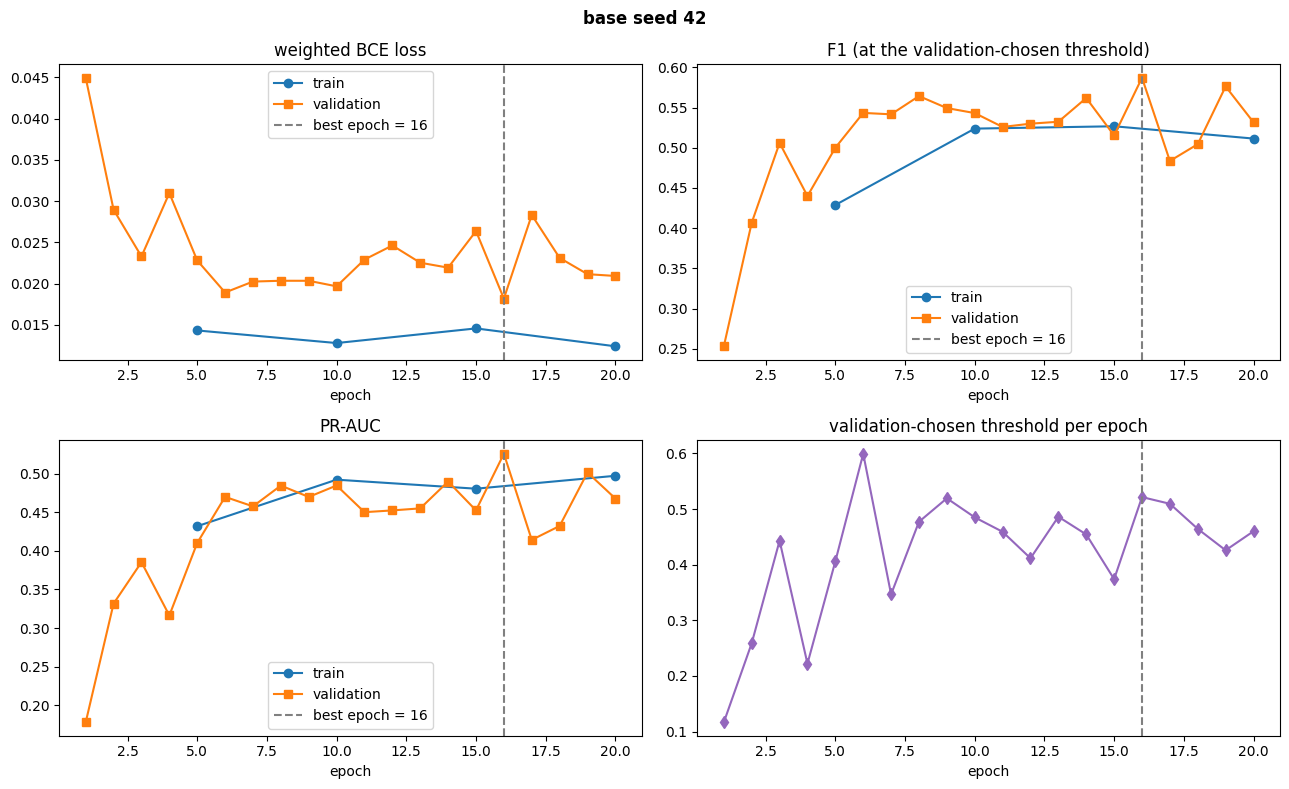

=== base seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,419 | architecture-invariant: 67,587


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0369 | F1   -    / 0.3095 @ 0.111 | PR-AUC   -    / 0.2241 | 51s | RAM 7.0GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 32 | loss   -    / 0.0174 | F1   -    / 0.5713 @ 0.671 | PR-AUC   -    / 0.5206 | 50s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 33 | loss   -    / 0.0205 | F1   -    / 0.5574 @ 0.560 | PR-AUC   -    / 0.4911 | 50s | RAM 7.1GB   (train / val)
early stop at epoch 33: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5994 at epoch 22 (threshold 0.492) | 33 of 100 epochs run


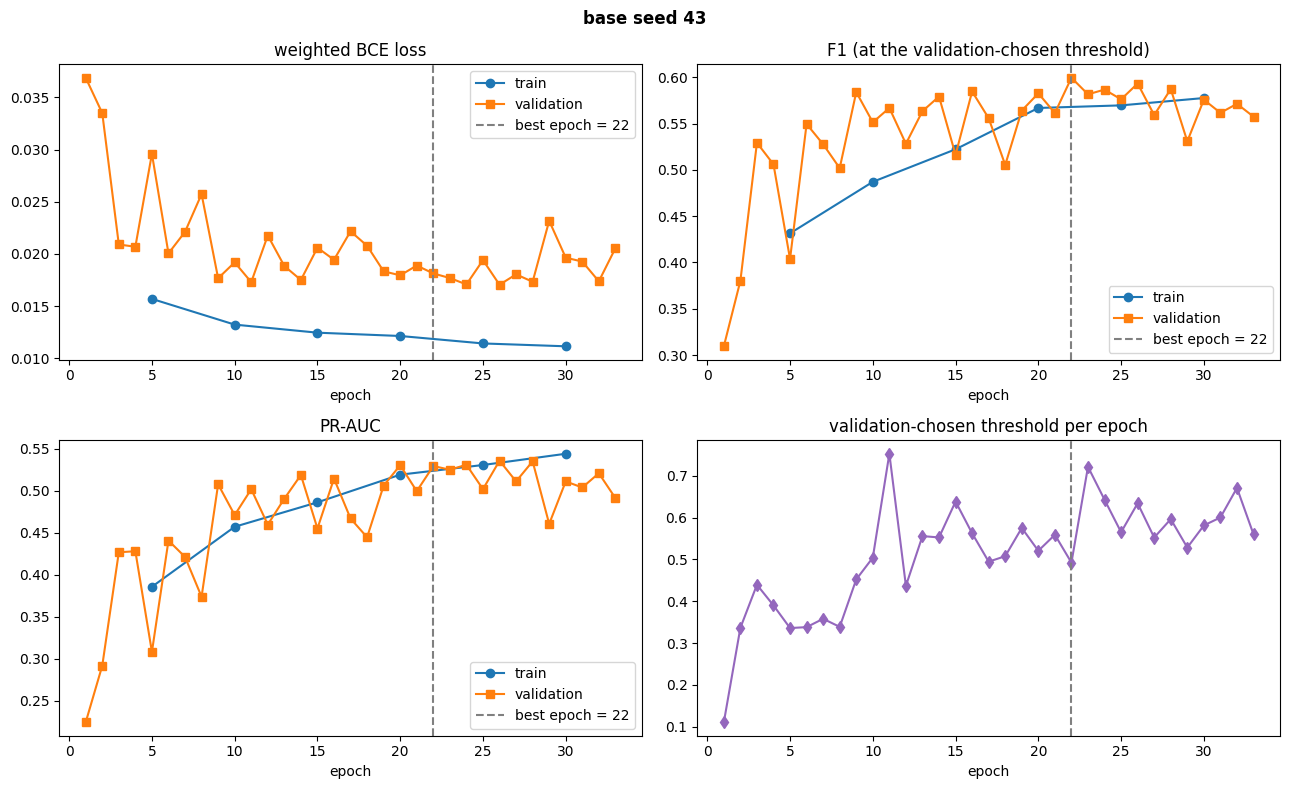

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 20:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 20:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 20:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 33 | loss   -    / 0.0203 | F1   -    / 0.5720 @ 0.589 | PR-AUC   -    / 0.5087 | 51s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 34 | loss   -    / 0.0201 | F1   -    / 0.5952 @ 0.653 | PR-AUC   -    / 0.5266 | 50s | RAM 7.5GB   (train / val)
early stop at epoch 34: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6092 at epoch 23 (threshold 0.554) | 34 of 100 epochs run


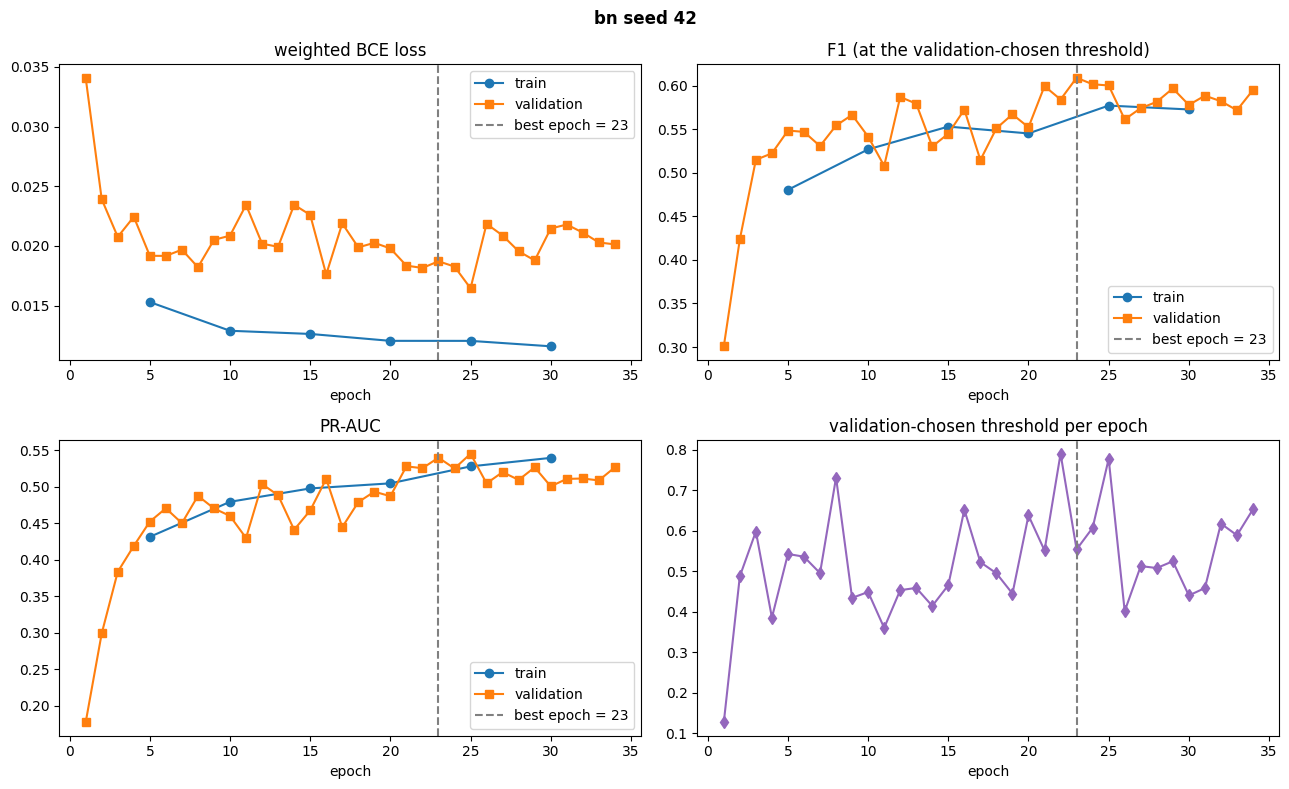

=== bn seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0374 | F1   -    / 0.3370 @ 0.125 | PR-AUC   -    / 0.2239 | 51s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 43 | loss   -    / 0.0176 | F1   -    / 0.6208 @ 0.696 | PR-AUC   -    / 0.5655 | 50s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 44 | loss   -    / 0.0235 | F1   -    / 0.5464 @ 0.760 | PR-AUC   -    / 0.4825 | 51s | RAM 7.1GB   (train / val)
early stop at epoch 44: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6220 at epoch 34 (threshold 0.656) | 44 of 100 epochs run


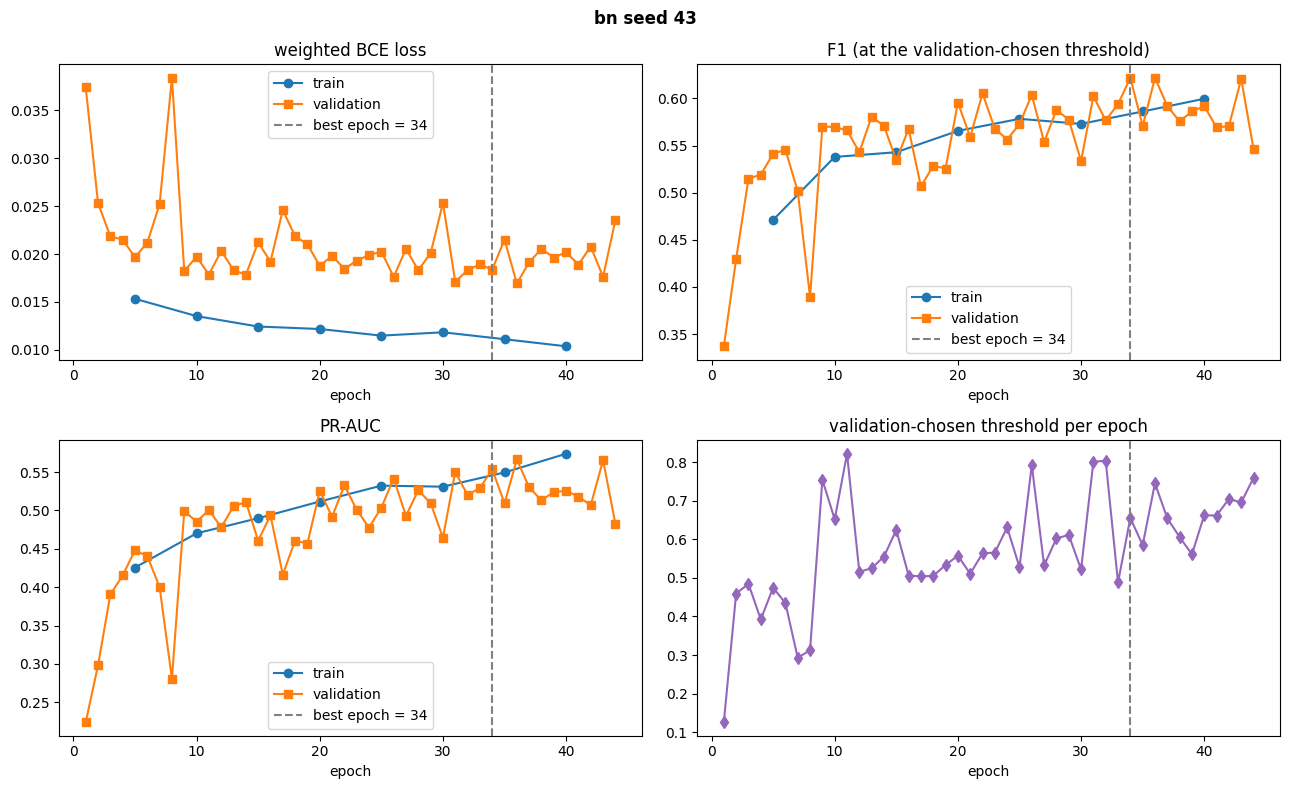

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 34:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 34:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 34:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 33 | loss   -    / 0.0203 | F1   -    / 0.5508 @ 0.568 | PR-AUC   -    / 0.4956 | 51s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 34 | loss   -    / 0.0180 | F1   -    / 0.6102 @ 0.746 | PR-AUC   -    / 0.5584 | 50s | RAM 7.5GB   (train / val)
early stop at epoch 34: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6292 at epoch 23 (threshold 0.735) | 34 of 100 epochs run


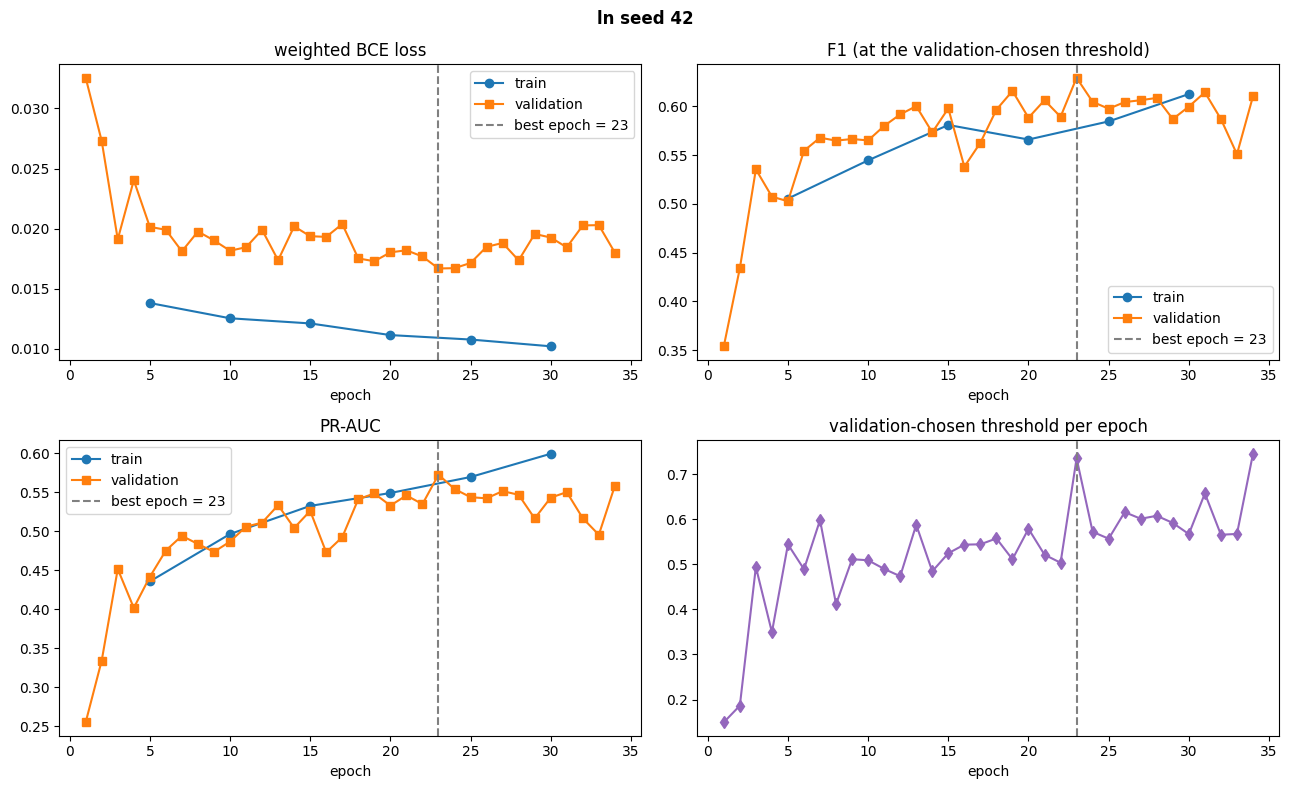

=== ln seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0347 | F1   -    / 0.3399 @ 0.106 | PR-AUC   -    / 0.2605 | 51s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 28 | loss   -    / 0.0193 | F1   -    / 0.5885 @ 0.608 | PR-AUC   -    / 0.5238 | 50s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 29 | loss   -    / 0.0173 | F1   -    / 0.6242 @ 0.656 | PR-AUC   -    / 0.5569 | 51s | RAM 7.1GB   (train / val)   * new best -> best.pt
early stop at epoch 29: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6242 at epoch 29 (threshold 0.656) | 29 of 100 epochs run


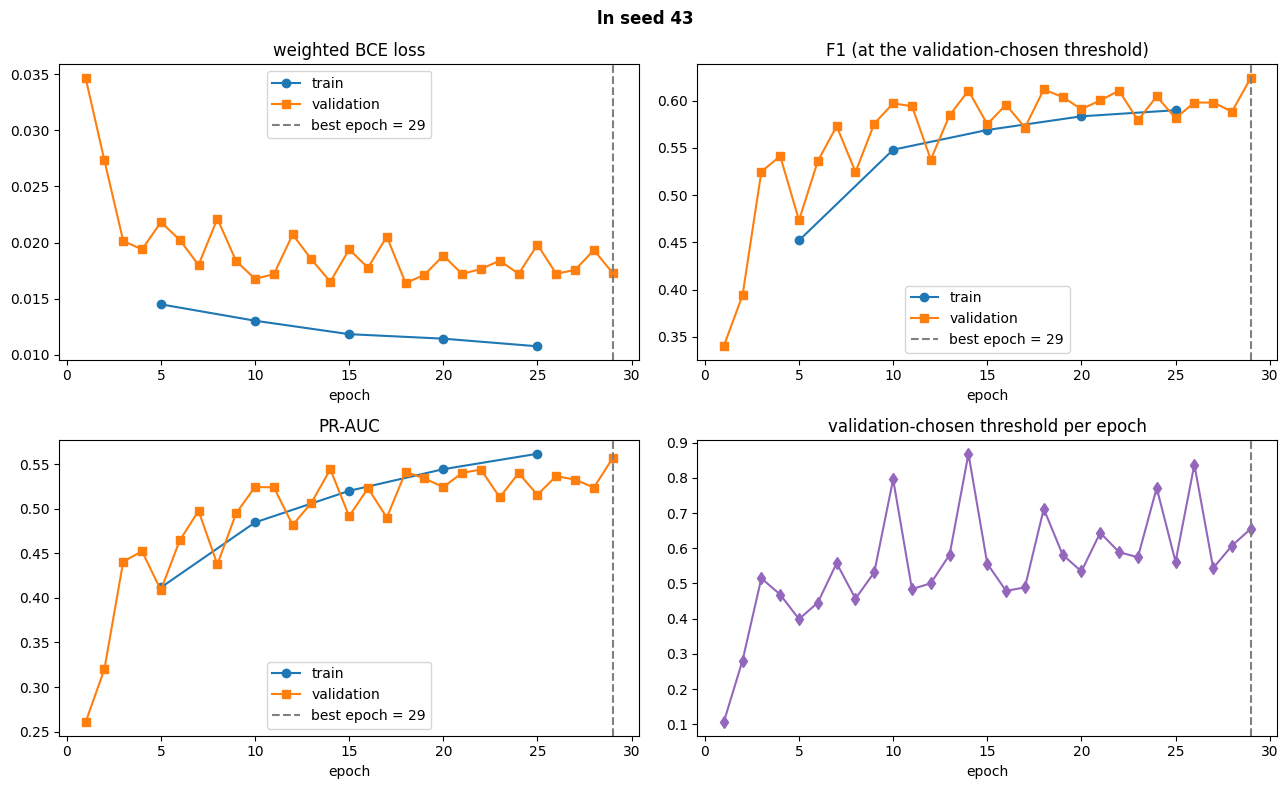

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 23:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 23:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 23:   0%|          | 0/372 [00:00<?, ?it/s]

...

epoch 29 | loss   -    / 0.0170 | F1   -    / 0.5950 @ 0.680 | PR-AUC   -    / 0.5467 | 107s | RAM 7.4GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 30 | loss 0.0110 / 0.0222 | F1 0.5867 / 0.5910 @ 0.517 | PR-AUC 0.5618 / 0.5180 | 168s | RAM 7.4GB   (train / val)
early stop at epoch 30: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6039 at epoch 19 (threshold 0.541) | 30 of 100 epochs run


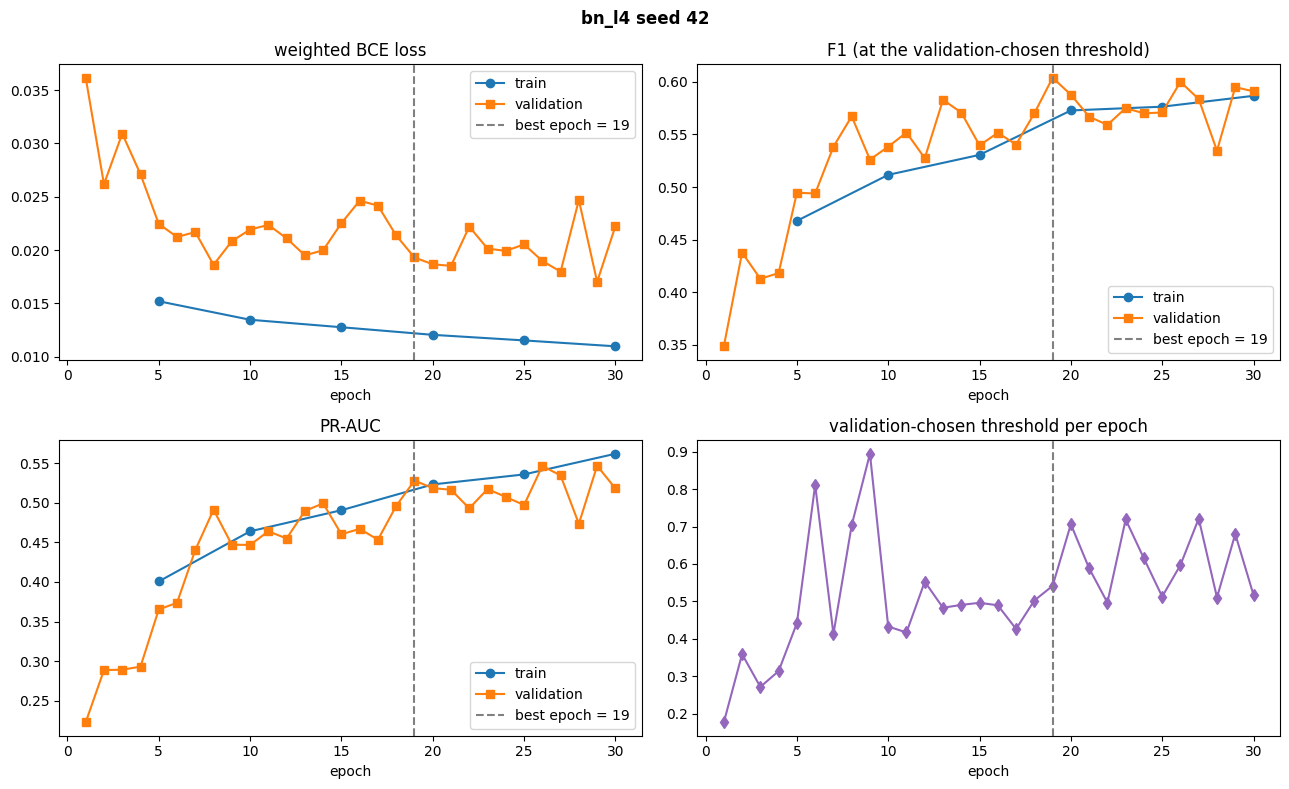

=== bn_l4 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 181,381 | architecture-invariant: 135,173


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0381 | F1   -    / 0.3189 @ 0.084 | PR-AUC   -    / 0.1830 | 108s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 50 | loss 0.0100 / 0.0247 | F1 0.5970 / 0.5689 @ 0.608 | PR-AUC 0.5855 / 0.5039 | 166s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 51 | loss   -    / 0.0246 | F1   -    / 0.5407 @ 0.652 | PR-AUC   -    / 0.4813 | 108s | RAM 7.1GB   (train / val)
early stop at epoch 51: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6185 at epoch 41 (threshold 0.630) | 51 of 100 epochs run


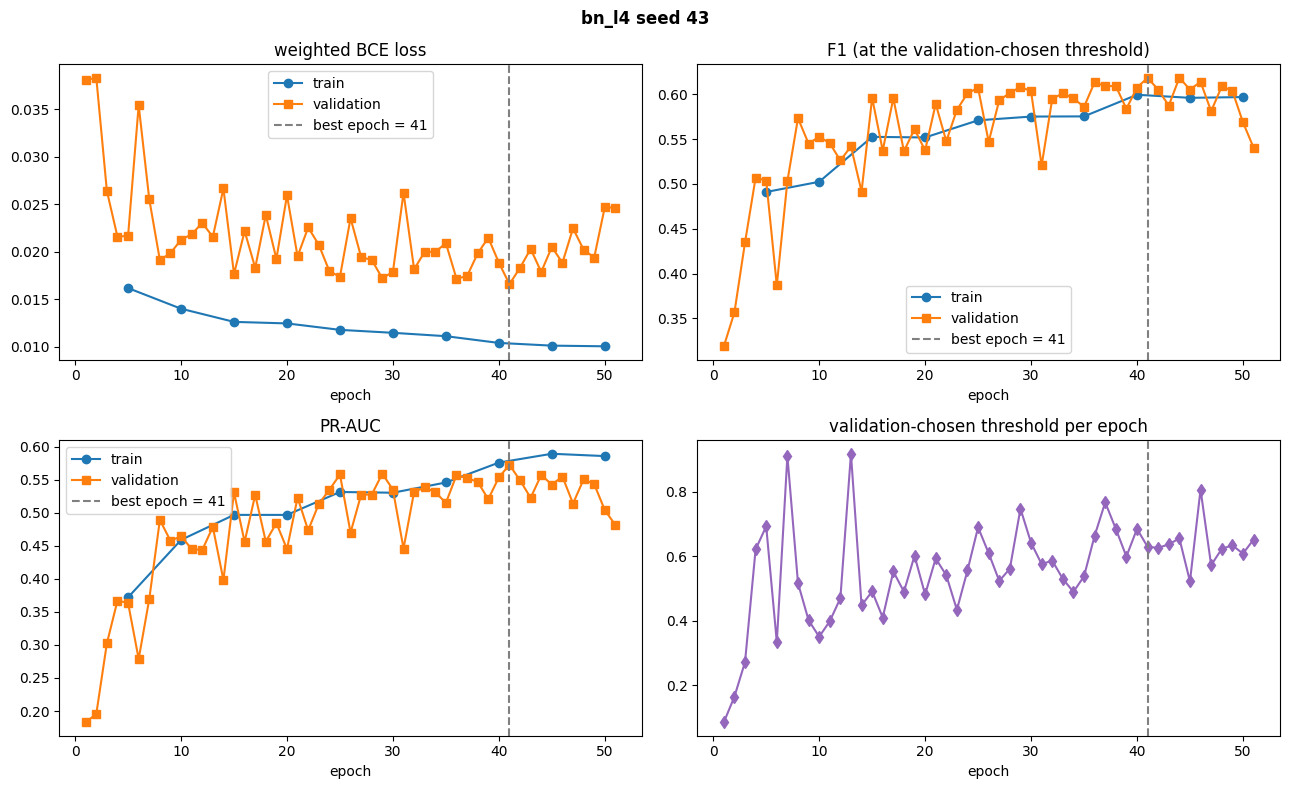

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 30:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 30:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 30:   0%|          | 0/372 [00:00<?, ?it/s]

...

epoch 19 | loss   -    / 0.0201 | F1   -    / 0.5615 @ 0.523 | PR-AUC   -    / 0.4907 | 80s | RAM 7.8GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 20 | loss 0.0119 / 0.0183 | F1 0.5788 / 0.5816 @ 0.705 | PR-AUC 0.5235 / 0.5246 | 127s | RAM 7.7GB   (train / val)
early stop at epoch 20: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5847 at epoch 8 (threshold 0.424) | 20 of 100 epochs run


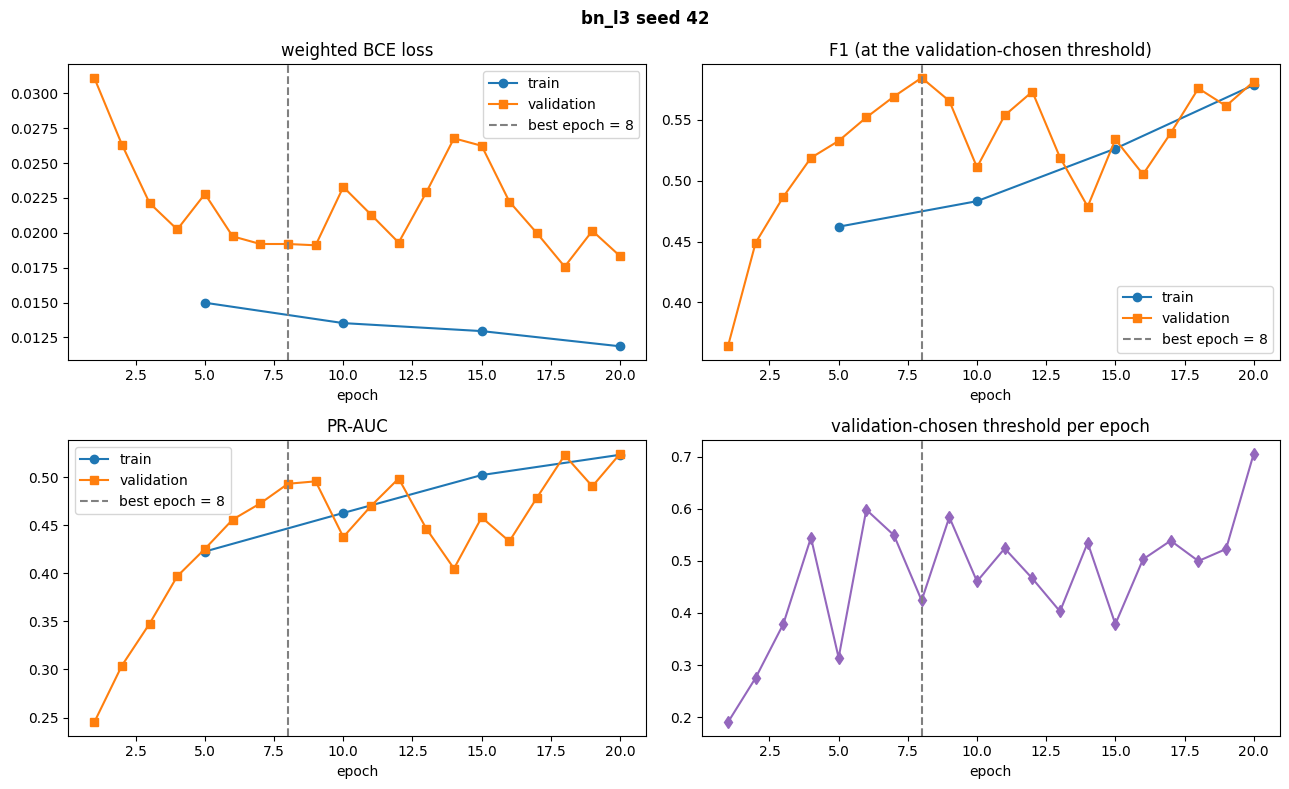

=== bn_l3 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 145,156 | architecture-invariant: 101,636


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0367 | F1   -    / 0.2805 @ 0.245 | PR-AUC   -    / 0.1581 | 79s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 38 | loss   -    / 0.0189 | F1   -    / 0.5856 @ 0.807 | PR-AUC   -    / 0.5388 | 79s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 39 | loss   -    / 0.0257 | F1   -    / 0.5282 @ 0.574 | PR-AUC   -    / 0.4727 | 79s | RAM 7.1GB   (train / val)
early stop at epoch 39: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6209 at epoch 34 (threshold 0.741) | 39 of 100 epochs run


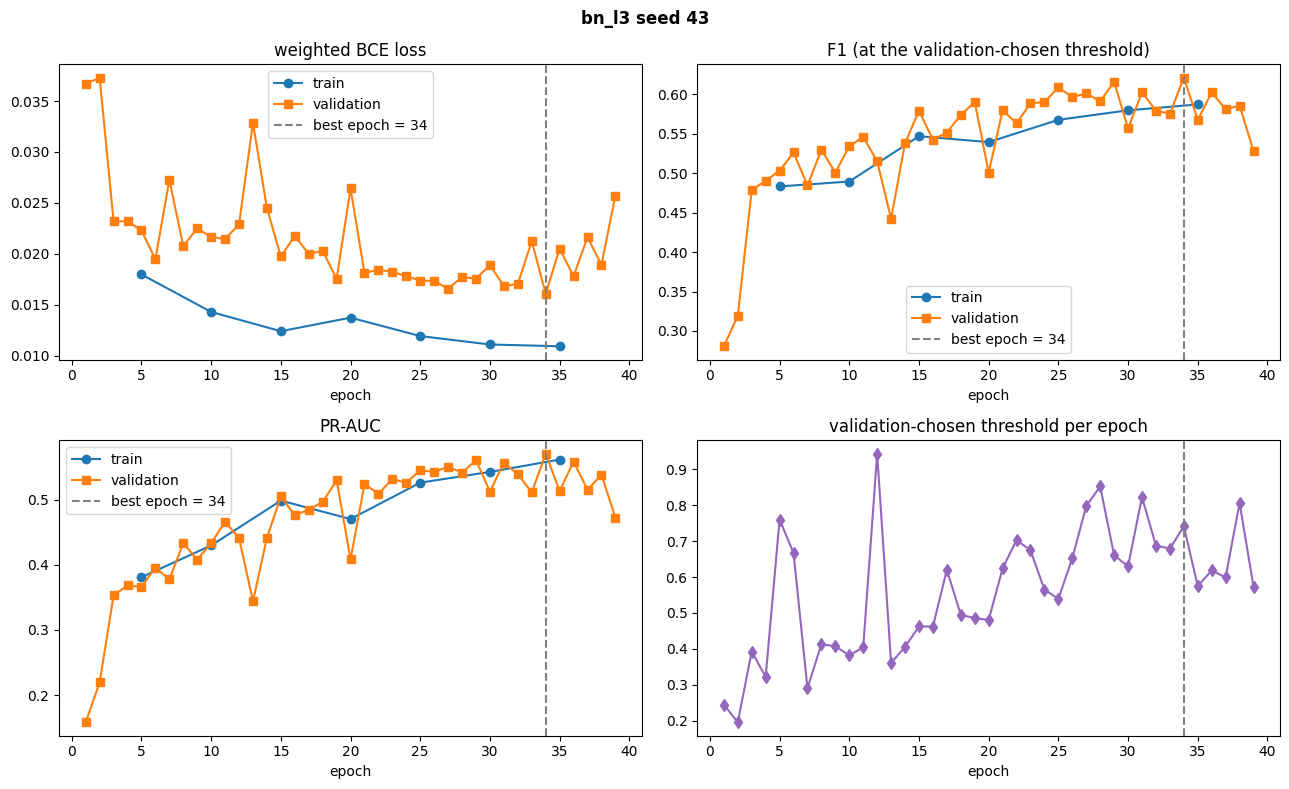

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 18:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 18:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 18:   0%|          | 0/372 [00:00<?, ?it/s]

...

epoch 34 | loss   -    / 0.0184 | F1   -    / 0.5989 @ 0.770 | PR-AUC   -    / 0.5333 | 57s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 35 | loss 0.0105 / 0.0182 | F1 0.5975 / 0.5856 @ 0.676 | PR-AUC 0.5735 / 0.5322 | 90s | RAM 7.5GB   (train / val)
early stop at epoch 35: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6213 at epoch 25 (threshold 0.777) | 35 of 100 epochs run


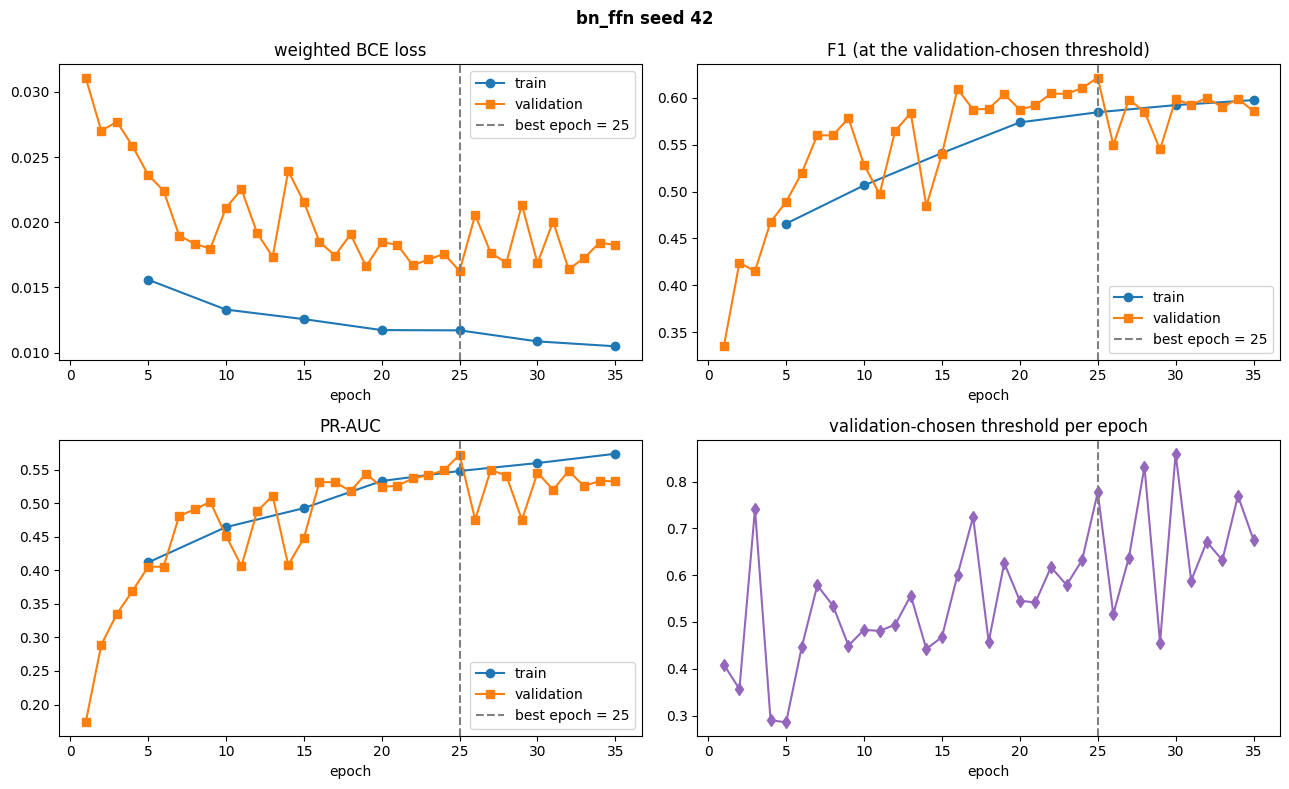

=== bn_ffn seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 241,283 | architecture-invariant: 200,451


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0437 | F1   -    / 0.2924 @ 0.151 | PR-AUC   -    / 0.2137 | 58s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 26 | loss   -    / 0.0190 | F1   -    / 0.5748 @ 0.699 | PR-AUC   -    / 0.5350 | 57s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 27 | loss   -    / 0.0171 | F1   -    / 0.6115 @ 0.649 | PR-AUC   -    / 0.5478 | 57s | RAM 7.1GB   (train / val)   * new best -> best.pt
early stop at epoch 27: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6115 at epoch 27 (threshold 0.649) | 27 of 100 epochs run


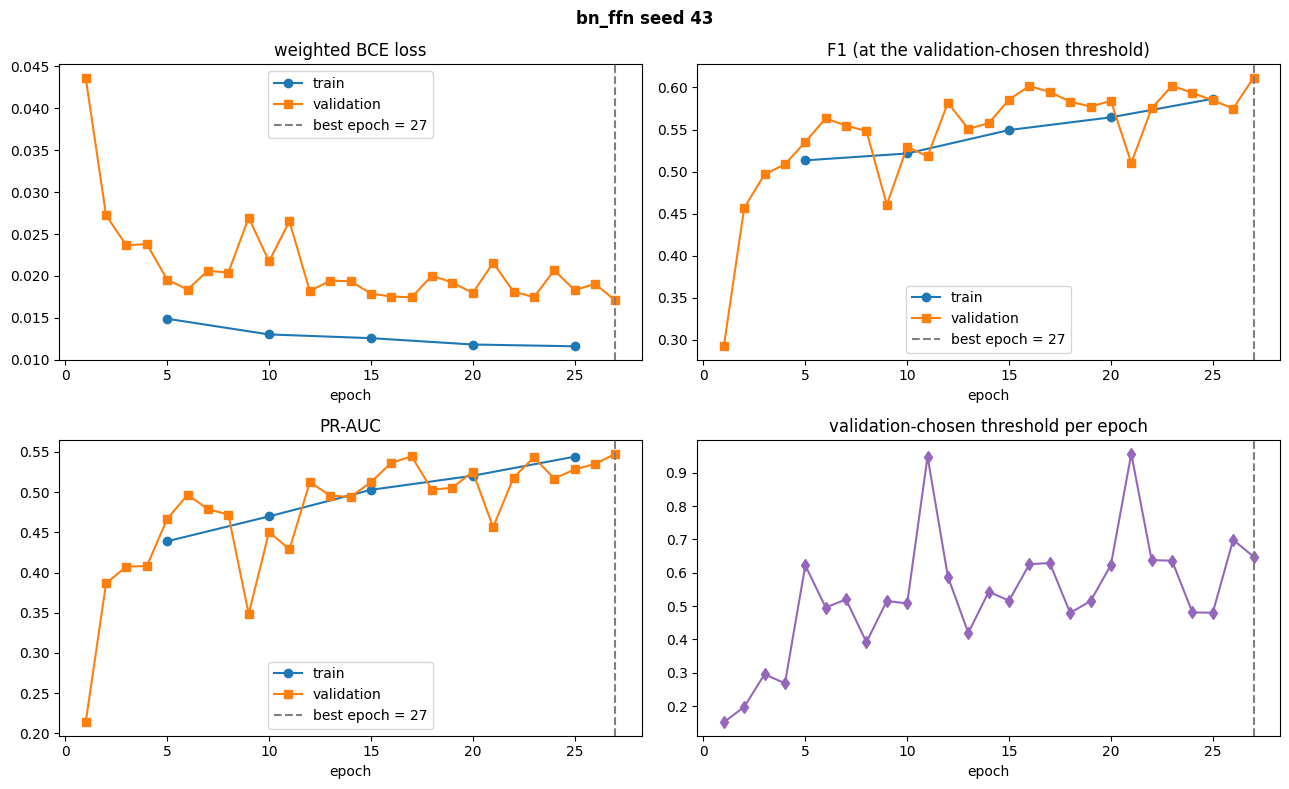

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 24:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 24:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 24:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 41 | loss   -    / 0.0509 | F1   -    / 0.5420 @ 0.777 | PR-AUC   -    / 0.4609 | 51s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 42 | loss   -    / 0.0312 | F1   -    / 0.5984 @ 0.821 | PR-AUC   -    / 0.5464 | 51s | RAM 7.5GB   (train / val)
early stop at epoch 42: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6111 at epoch 35 (threshold 0.764) | 42 of 100 epochs run


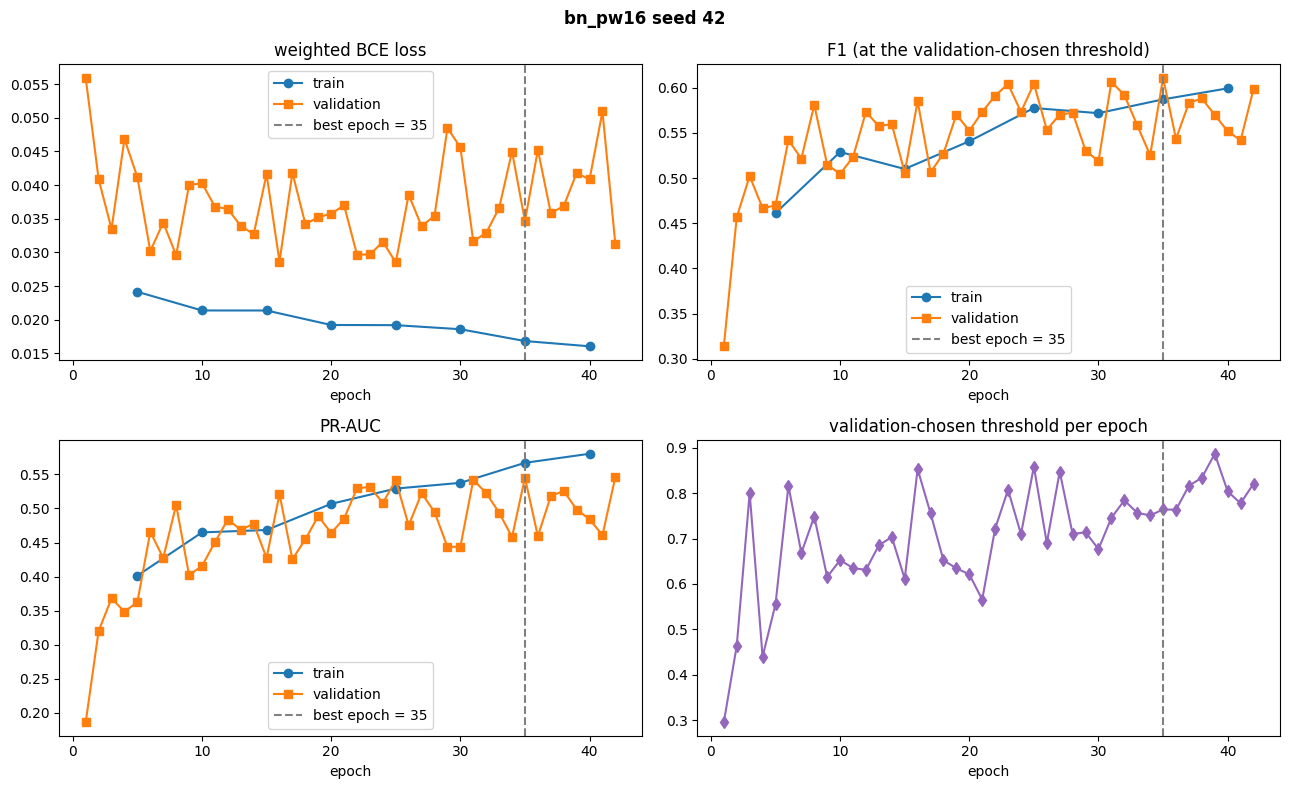

=== bn_pw16 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0573 | F1   -    / 0.3438 @ 0.237 | PR-AUC   -    / 0.2527 | 50s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 42 | loss   -    / 0.0457 | F1   -    / 0.5285 @ 0.786 | PR-AUC   -    / 0.4723 | 50s | RAM 7.2GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 43 | loss   -    / 0.0359 | F1   -    / 0.5915 @ 0.810 | PR-AUC   -    / 0.5431 | 51s | RAM 7.2GB   (train / val)
early stop at epoch 43: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6064 at epoch 28 (threshold 0.750) | 43 of 100 epochs run


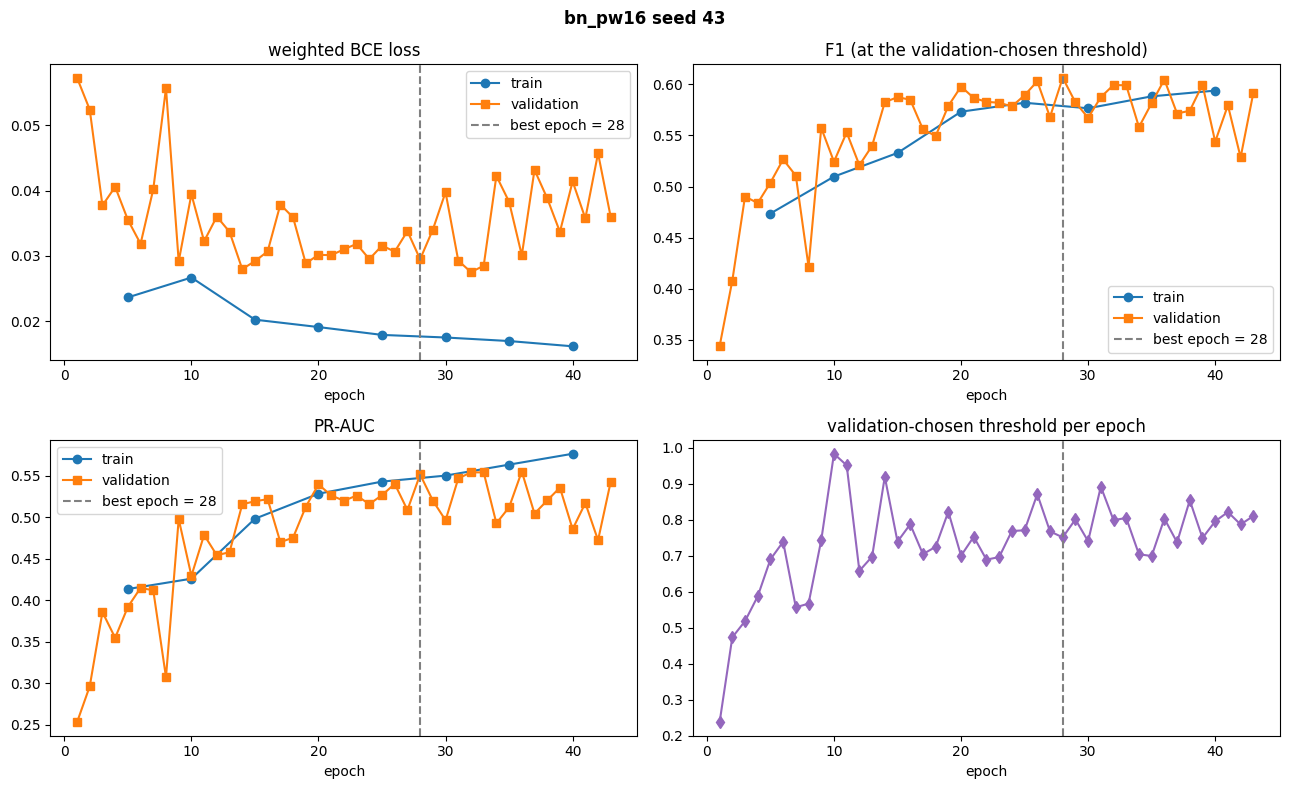

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 32:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 32:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 32:   0%|          | 0/372 [00:00<?, ?it/s]

...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 30 | loss 0.0080 / 0.0164 | F1 0.5214 / 0.4822 @ 0.227 | PR-AUC 0.4967 / 0.4175 | 83s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 31 | loss   -    / 0.0105 | F1   -    / 0.5918 @ 0.478 | PR-AUC   -    / 0.5338 | 50s | RAM 7.5GB   (train / val)
early stop at epoch 31: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6133 at epoch 23 (threshold 0.333) | 31 of 100 epochs run


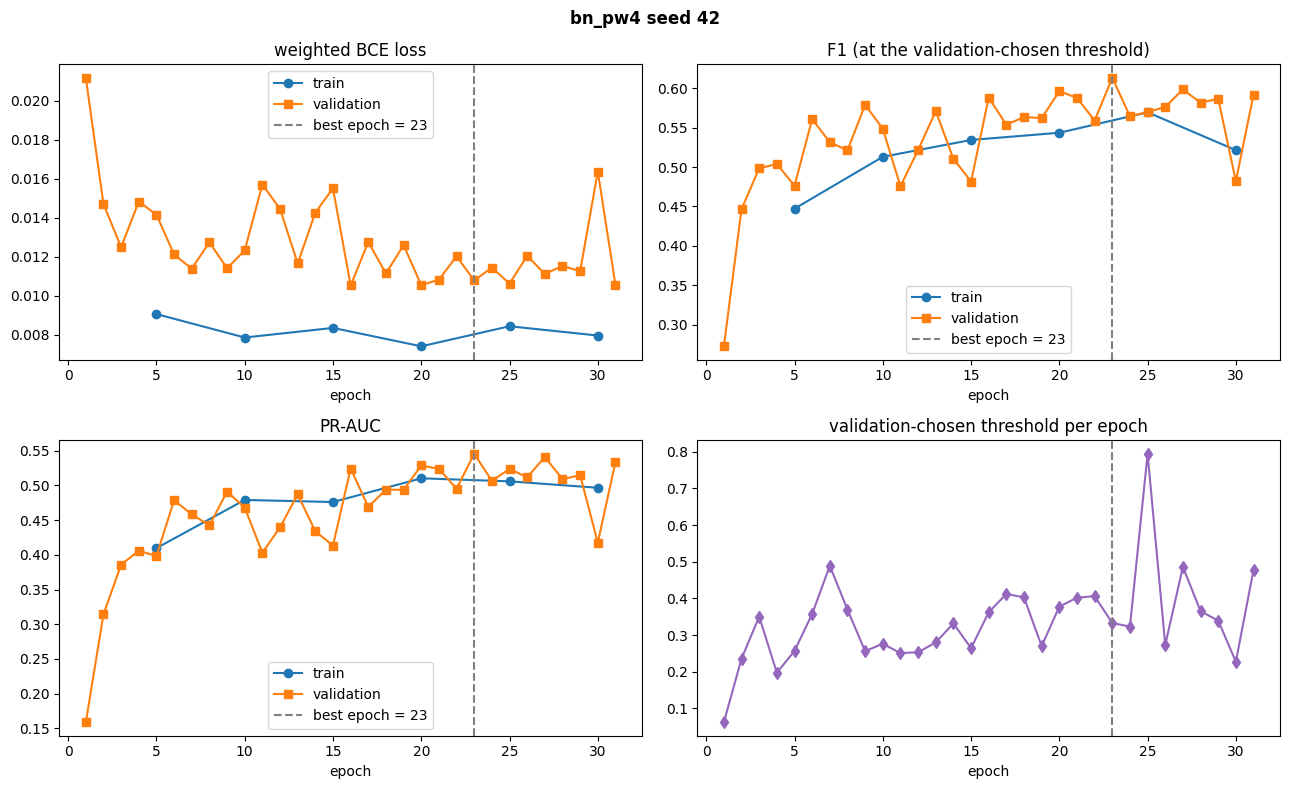

=== bn_pw4 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0195 | F1   -    / 0.3288 @ 0.088 | PR-AUC   -    / 0.2178 | 51s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 45 | loss 0.0063 / 0.0117 | F1 0.6039 / 0.5663 @ 0.518 | PR-AUC 0.5809 / 0.5238 | 83s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 46 | loss   -    / 0.0107 | F1   -    / 0.6183 @ 0.468 | PR-AUC   -    / 0.5603 | 50s | RAM 7.1GB   (train / val)
early stop at epoch 46: smoothed val F1 has not improved for 10 epochs
best validation F1 0.6284 at epoch 36 (threshold 0.476) | 46 of 100 epochs run


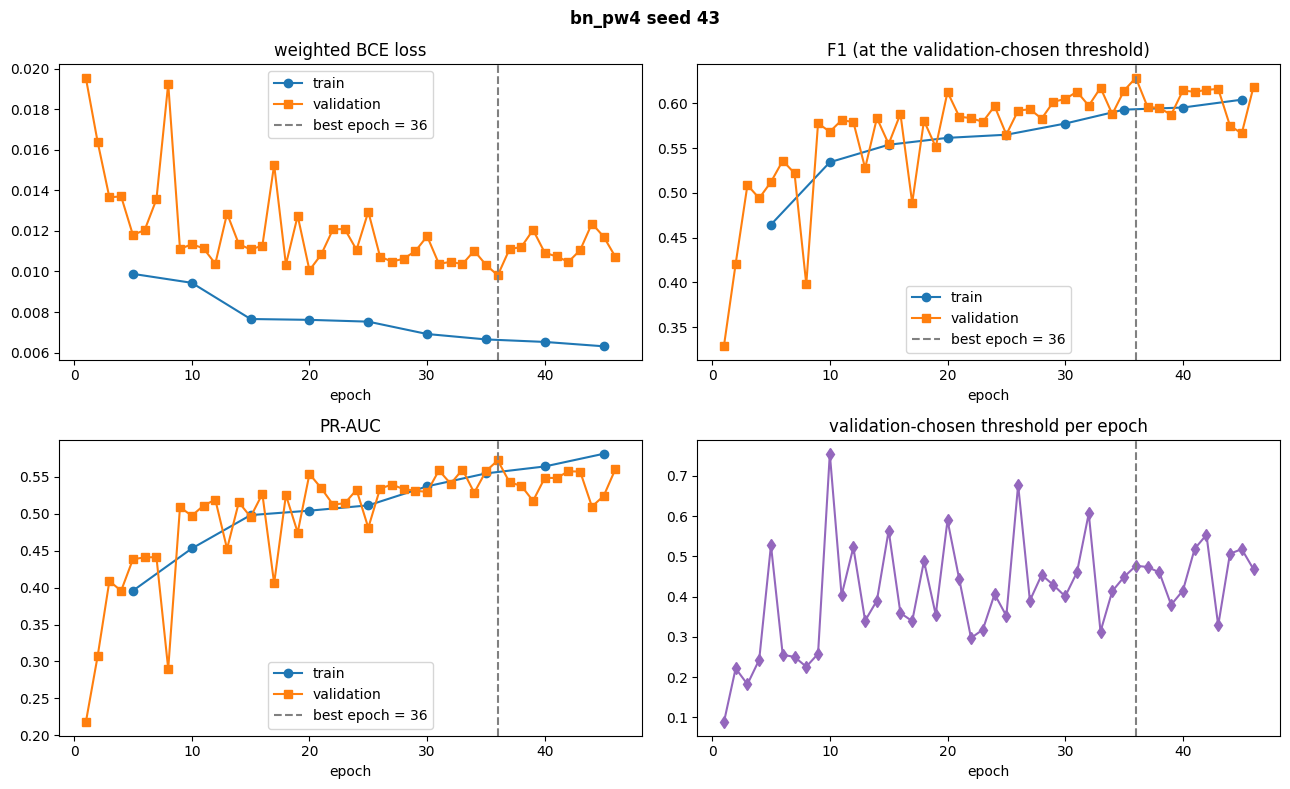

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 42 @ epoch 28:   0%|          | 0/372 [00:00<?, ?it/s]

predict val seed 42 @ epoch 28:   0%|          | 0/124 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


predict train seed 43 @ epoch 28:   0%|          | 0/372 [00:00<?, ?it/s]

...

epoch 19 | loss   -    / 0.0213 | F1   -    / 0.5368 @ 0.450 | PR-AUC   -    / 0.4797 | 50s | RAM 7.5GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 20 | loss 0.0128 / 0.0230 | F1 0.5136 / 0.5191 @ 0.467 | PR-AUC 0.4774 / 0.4493 | 84s | RAM 7.5GB   (train / val)
early stop at epoch 20: smoothed val F1 has not improved for 10 epochs
best validation F1 0.5666 at epoch 14 (threshold 0.599) | 20 of 100 epochs run


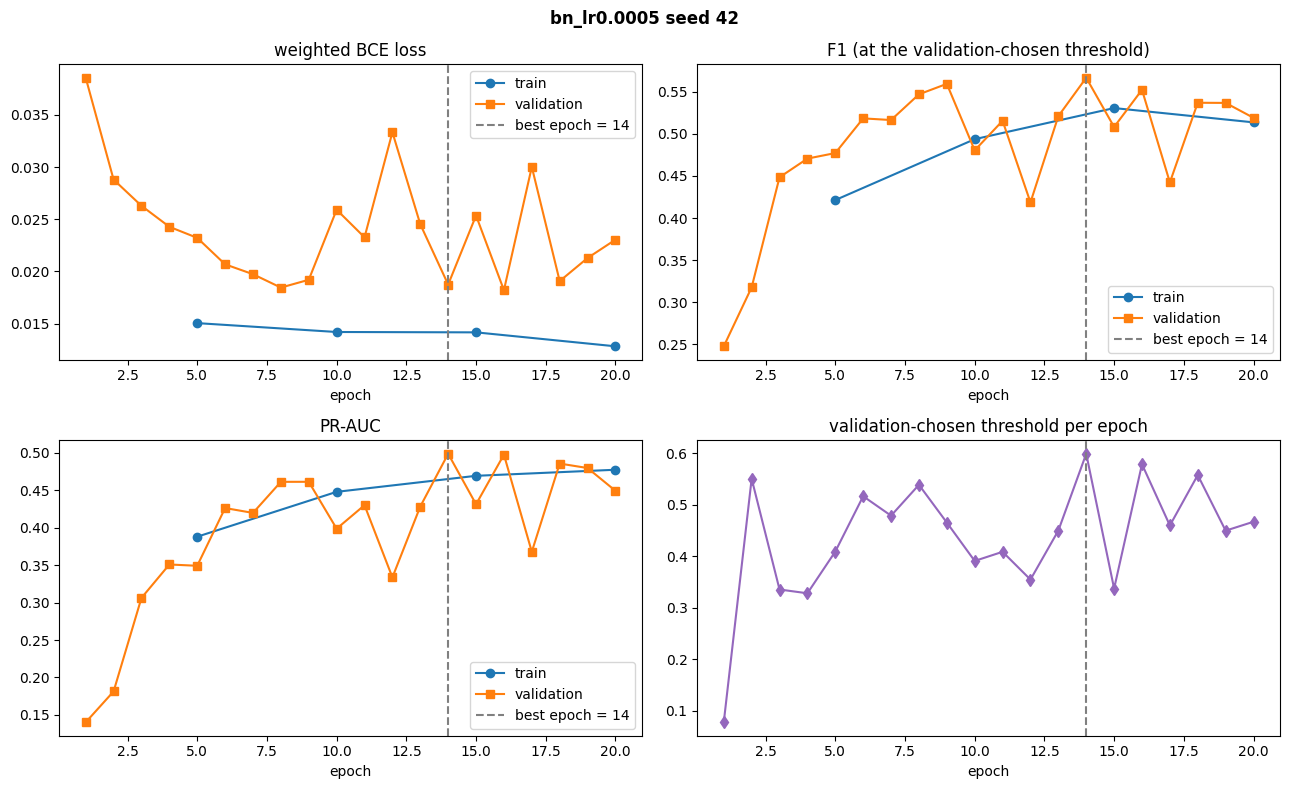

=== bn_lr0.0005 seed 43 ===
MP edge features: 20 | readout edge features: 20 | node features: 6
total params: 108,931 | architecture-invariant: 68,099


/usr/local/lib/python3.13/dist-packages/torch_geometric/loader/link_neighbor_loader.py:252: UserWarning: Using 'NeighborSampler' without a 'pyg-lib' installation is deprecated and will be removed soon. Please install 'pyg-lib' for accelerated neighborhood sampling
  neighbor_sampler = NeighborSampler(


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 01 | loss   -    / 0.0415 | F1   -    / 0.2493 @ 0.103 | PR-AUC   -    / 0.1422 | 51s | RAM 7.1GB   (train / val)   * new best -> best.pt


...

epoch 27 | loss   -    / 0.0334 | F1   -    / 0.4378 @ 0.512 | PR-AUC   -    / 0.3669 | 50s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

predict val:   0%|          | 0/124 [00:00<?, ?it/s]

epoch 28 | loss   -    / 0.0185 | F1   -    / 0.5805 @ 0.611 | PR-AUC   -    / 0.5212 | 50s | RAM 7.1GB   (train / val)


train:   0%|          | 0/372 [00:00<?, ?it/s]

In [6]:
incumbent = core.full_recipe(TUNE)          # the v1 recipe + T_max 100; each stage may replace one knob
incumbent_trial, winners = None, {}
for stage, knob, grid in STAGES:
    stage_dir = f'{OUT_ROOT}/{stage}'
    os.makedirs(stage_dir, exist_ok=True)
    trials, recipes = [], {}
    for value in grid:
        recipe = core.with_knob(incumbent, knob, value, NEIGHBOURS_USED)
        if recipe is None:
            print(f'{stage}: {knob} = {value} skipped (depth dropped by the probe)')
            continue
        trial = core.run_tuning_trial(OPERATOR, CFG, graphs, col_sets, node_dim, stage_dir, recipe, SEEDS, TUNE,
                                      MP_DIRECTION, TEMPORAL_SAMPLING, EVAL_TRAIN_EVERY, PATIENCE, MIN_EPOCHS,
                                      reuse=incumbent_trial)
        trials.append(trial)
        recipes[trial['trial']] = recipe
    winner = core.choose_winner(trials, core.recipe_tag(incumbent, TUNE))

    # edge rule: a numeric winner at the edge of its grid gets one trial one step beyond
    beyond = core.edge_value(knob, winner['recipe'][knob], grid)
    if beyond is not None:
        if knob == 'num_layers' and beyond not in NEIGHBOURS_USED:
            extra_probe = core.probe_depths(OPERATOR, CFG, graphs, col_sets, node_dim, HEAVIEST, (beyond,),
                                            f'{OUT_ROOT}/probe_{beyond}L.json', mp_direction=MP_DIRECTION,
                                            temporal=TEMPORAL_SAMPLING, reference_seconds=probe['reference_seconds'])
            NEIGHBOURS_USED = core.neighbours_from_probe(extra_probe, NEIGHBOURS_USED)
        recipe = core.with_knob(winner['recipe'], knob, beyond, NEIGHBOURS_USED)
        if recipe is None:
            print(f'{stage}: edge trial {knob} = {beyond} skipped (depth failed the probe)')
        else:
            extra = core.run_tuning_trial(OPERATOR, CFG, graphs, col_sets, node_dim, stage_dir, recipe, SEEDS, TUNE,
                                          MP_DIRECTION, TEMPORAL_SAMPLING, EVAL_TRAIN_EVERY, PATIENCE, MIN_EPOCHS)
            trials.append(extra)
            recipes[extra['trial']] = recipe
            winner = core.choose_winner(trials, winner['trial'])

    incumbent, incumbent_trial, winners[stage] = recipes[winner['trial']], winner, winner['trial']
    core.summarize_stage(stage_dir, winner['trial'])
    print(f">>> after {stage}: incumbent = {winner['trial']} | best epoch {winner['best_epoch']} | {incumbent}")
print('=' * 90)
print('all stages complete | incumbent:', incumbent_trial['trial'], incumbent)

## 5. Summary across the stages

- `trials_summary.csv`: one row per trial with every knob, best / stopped epochs, train and validation F1 / PR-AUC (mean ± std), the train − val gap and the winner flag.
- Gap caveat: validation has 0.107 % laundering vs 0.075 % on train, so part of any gap is prevalence, not underfitting.
- `tuning_curves.png`: seed-mean validation F1 per epoch, one line per trial, winners bold.

In [ ]:
summary = core.summarize_tuning(OUT_ROOT, winners)
summary[['stage', 'trial', 'winner', 'dropout', 'norm', 'num_layers', 'num_neighbors', 'pos_weight', 'lr', 'ffn',
         'best_epoch', 'epochs_run', 'reached_max', 'val_f1_mean', 'val_f1_std', 'train_f1_mean', 'gap_f1',
         'val_pr_auc_mean', 'thresholds', 'params', 'invariant_params']].round(4)

## 6. Freeze the recipe

- Only after every stage has run: `recipe.json` = knobs, neighbour lists, T_max, best epoch, per-seed thresholds for the four retrain seeds (42 and 43 their own; 44 and 45 the mean of those two), the validation F1 that chose them.
- This file is the single source of the frozen GIN recipe; `GIN_tuning_final.ipynb` loads it.

In [ ]:
assert set(winners) == {stage for stage, _, _ in STAGES}, 'run every stage before freezing the recipe'
frozen = core.save_recipe(f'{OUT_ROOT}/recipe.json', OPERATOR, CFG, incumbent_trial)

## 7. Download

- Zip `OUT_ROOT`; extract into `Outputs/TUNING/GIN/` in the repo and commit the small files (`trial.json`, `history.csv`, `curves.png`, summaries, `probe.json`, `recipe.json`; `best.pt` stays out of git).

In [ ]:
import shutil
shutil.make_archive('/kaggle/working/Outputs_TUNING_GIN', 'zip', OUT_ROOT)